Load and Split

In [1]:
# Load and Split
import sys; sys.path.append("..")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from src.features import build_features, FEATURE_COLS, TARGET_COL
from src.models import segment_split, evaluate, get_models, persistence_baseline

df = pd.read_csv("../data/thermostat_log.csv", parse_dates=["timestamp"])

# --- NEW: Preserve original temperature mapping ---
temp_lookup = df.set_index("timestamp")["temperature"].to_dict()

feat = build_features(df)

train, test = segment_split(feat)
X_train, y_train = train[FEATURE_COLS], train[TARGET_COL]
X_test, y_test = test[FEATURE_COLS], test[TARGET_COL]

print(f"Train: {len(train)} rows (Autumn) | Test: {len(test)} rows (Early Winter)")
print(f"Test window: {test.timestamp.min()} → {test.timestamp.max()}")

# --- NEW: Reconstruct actual targets for real-world metrics ---
current_temp_test = test["timestamp"].map(temp_lookup).values
y_test_absolute = current_temp_test + y_test.values


Train: 6861 rows (Autumn) | Test: 822 rows (Early Winter)
Test window: 2026-11-03 14:25:05.376085 → 2026-11-06 12:00:06.226370


Train and Compare

In [2]:
# Train and compare
results = []
preds = {}

for name, model in get_models().items():
    # Trains to predict the DELTA
    model.fit(X_train, y_train)
    predicted_delta = model.predict(X_test)
    
    # --- NEW: Reconstruct absolute temperature predictions ---
    y_pred_absolute = current_temp_test + predicted_delta
    preds[name] = y_pred_absolute
    
    # Evaluate against the real-world temperatures
    results.append(evaluate(y_test_absolute, y_pred_absolute, name))

# --- NEW: Adjusted Persistence baseline to evaluate against absolute targets ---
persistence_pred_absolute = current_temp_test
preds["Persistence"] = persistence_pred_absolute
results.append(evaluate(y_test_absolute, persistence_pred_absolute, "Persistence"))

res_df = pd.DataFrame(results).sort_values("RMSE")
print(res_df.to_string(index=False))


           model     RMSE      MAE       R2
LinearRegression 0.363007 0.267410 0.882210
     Persistence 0.395842 0.300973 0.859937
    RandomForest 0.434484 0.331022 0.831257
         XGBoost 0.448554 0.342088 0.820151


Visualise predictions

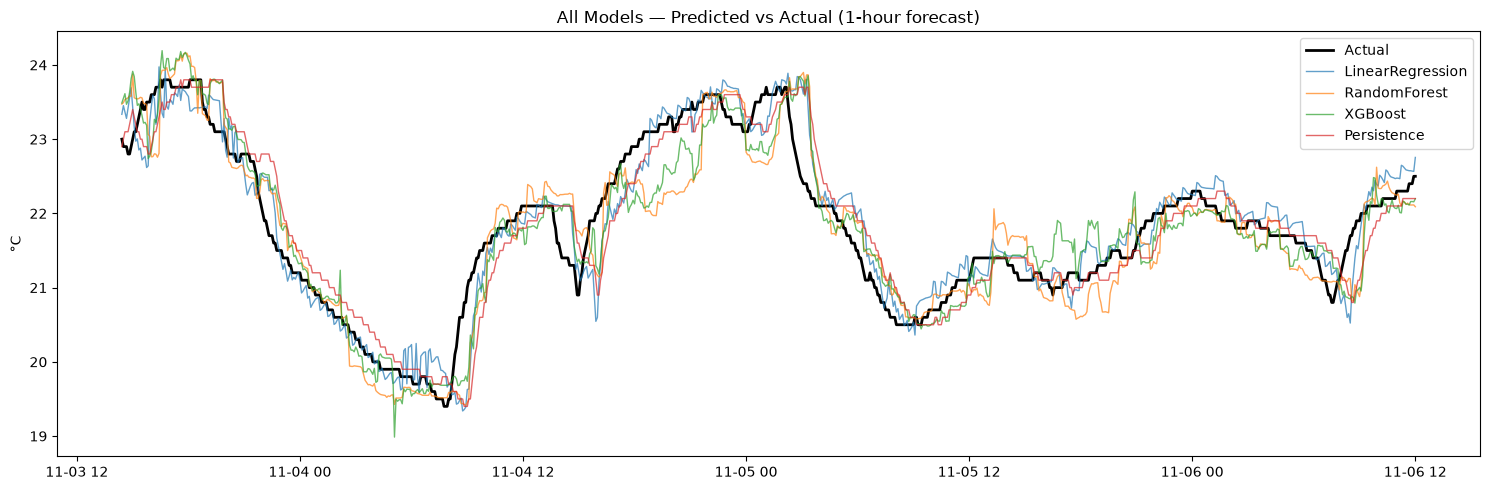

In [3]:
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(test.timestamp, y_test.values, label="Actual", color="black", lw=2)
for name, p in preds.items():
    ax.plot(test.timestamp, p, label=name, alpha=0.7, lw=1)
ax.set_title("All Models — Predicted vs Actual (1-hour forecast)")
ax.set_ylabel("°C"); ax.legend()
plt.tight_layout(); plt.show()

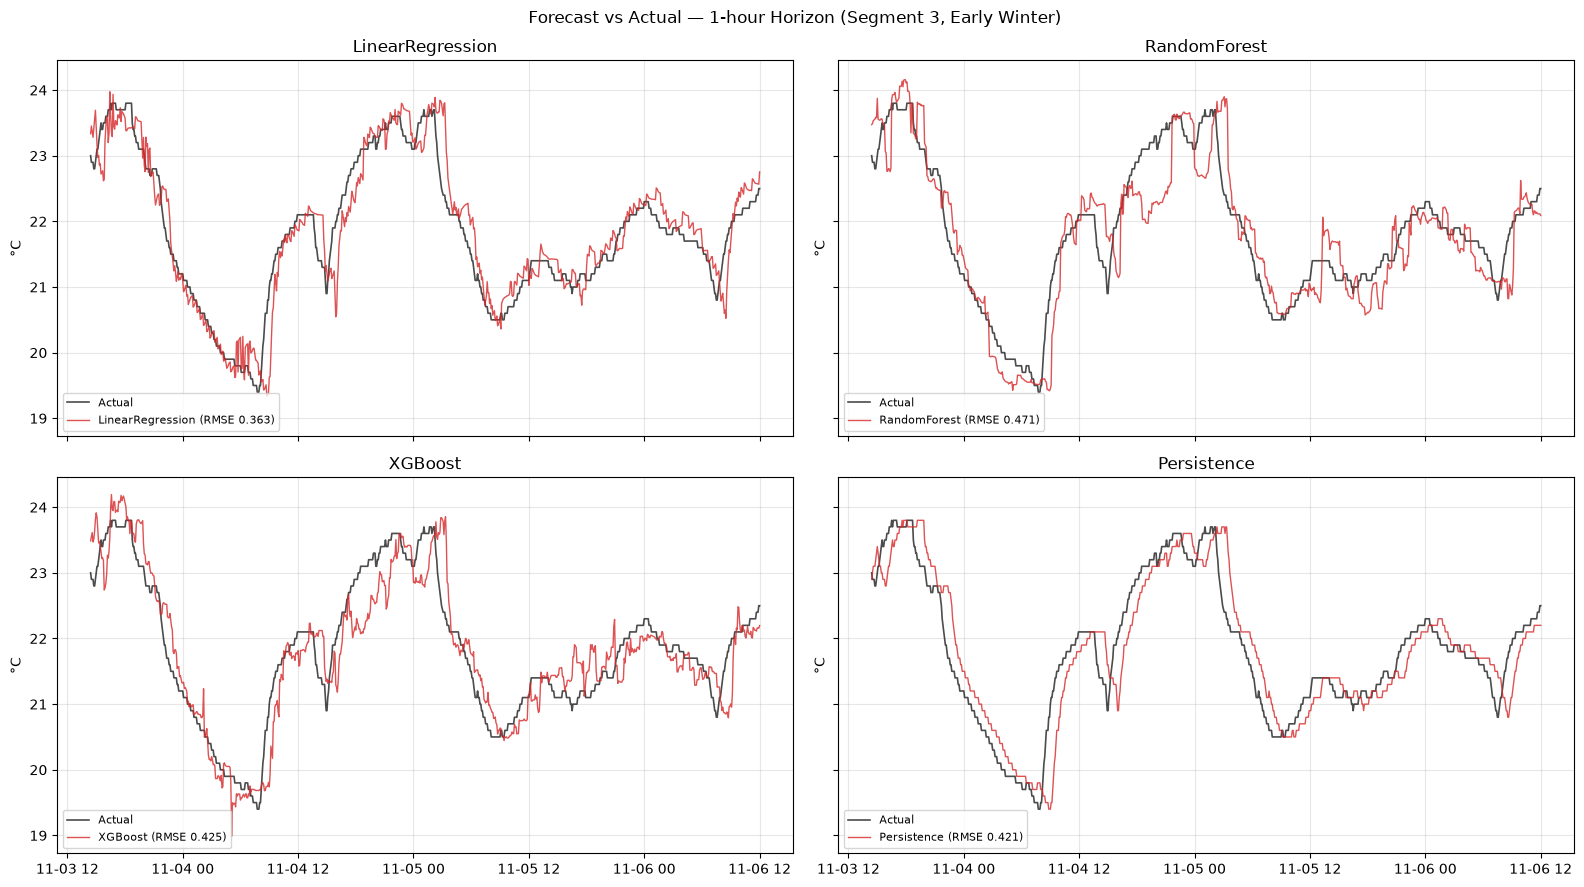

In [4]:
# Cell B — per-model grid (add this)
fig, axes = plt.subplots(2, 2, figsize=(16, 9), sharex=True, sharey=True)
axes = axes.flatten()

for ax, (name, p) in zip(axes, preds.items()):
    rmse = res_df.loc[res_df.model == name, 'RMSE'].values[0]
    ax.plot(test.timestamp, y_test.values, label="Actual", color="black", lw=1.2, alpha=0.7)
    ax.plot(test.timestamp, p, label=f"{name} (RMSE {rmse:.3f})", color="tab:red", lw=1, alpha=0.8)
    ax.set_title(name)
    ax.set_ylabel("°C")
    ax.legend(loc="lower left", fontsize=8)
    ax.grid(alpha=0.3)

plt.suptitle("Forecast vs Actual — 1-hour Horizon (Segment 3, Early Winter)")
plt.tight_layout()
plt.show()

Feature Importance

Best Model: LinearRegression


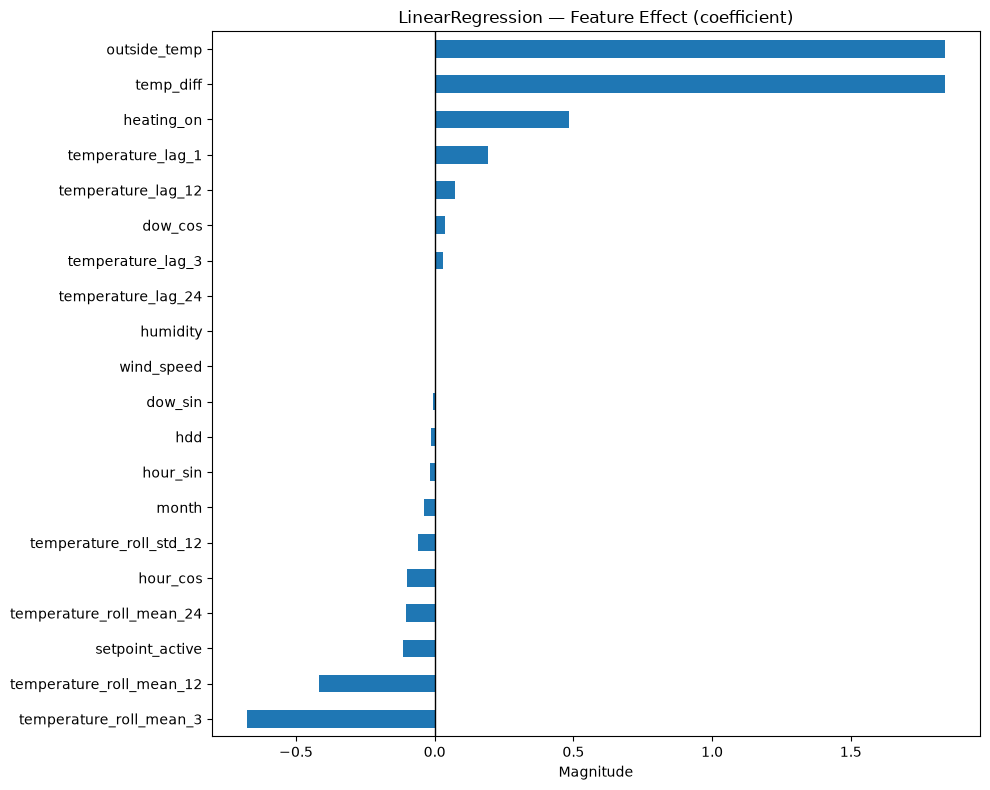

In [8]:
best_model_name = res_df.iloc[0]["model"]
print(f"Best Model: {best_model_name}")

model = get_models()[best_model_name]
model.fit(X_train, y_train)

if hasattr(model, "feature_importances_"):
    # Tree models: use feature_importances_
    imp = pd.Series(model.feature_importances_, index=FEATURE_COLS)
    title = f"{best_model_name} — Feature Importance"
else:
    # Linear Regression: use coef_ 
    imp = pd.Series(model.coef_, index=FEATURE_COLS)
    title = f"{best_model_name} — Feature Effect (coefficient)"

imp.sort_values().plot.barh(figsize=(10, 8), title=title)
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Magnitude")
plt.tight_layout()
plt.show()

Feature Importance for all models

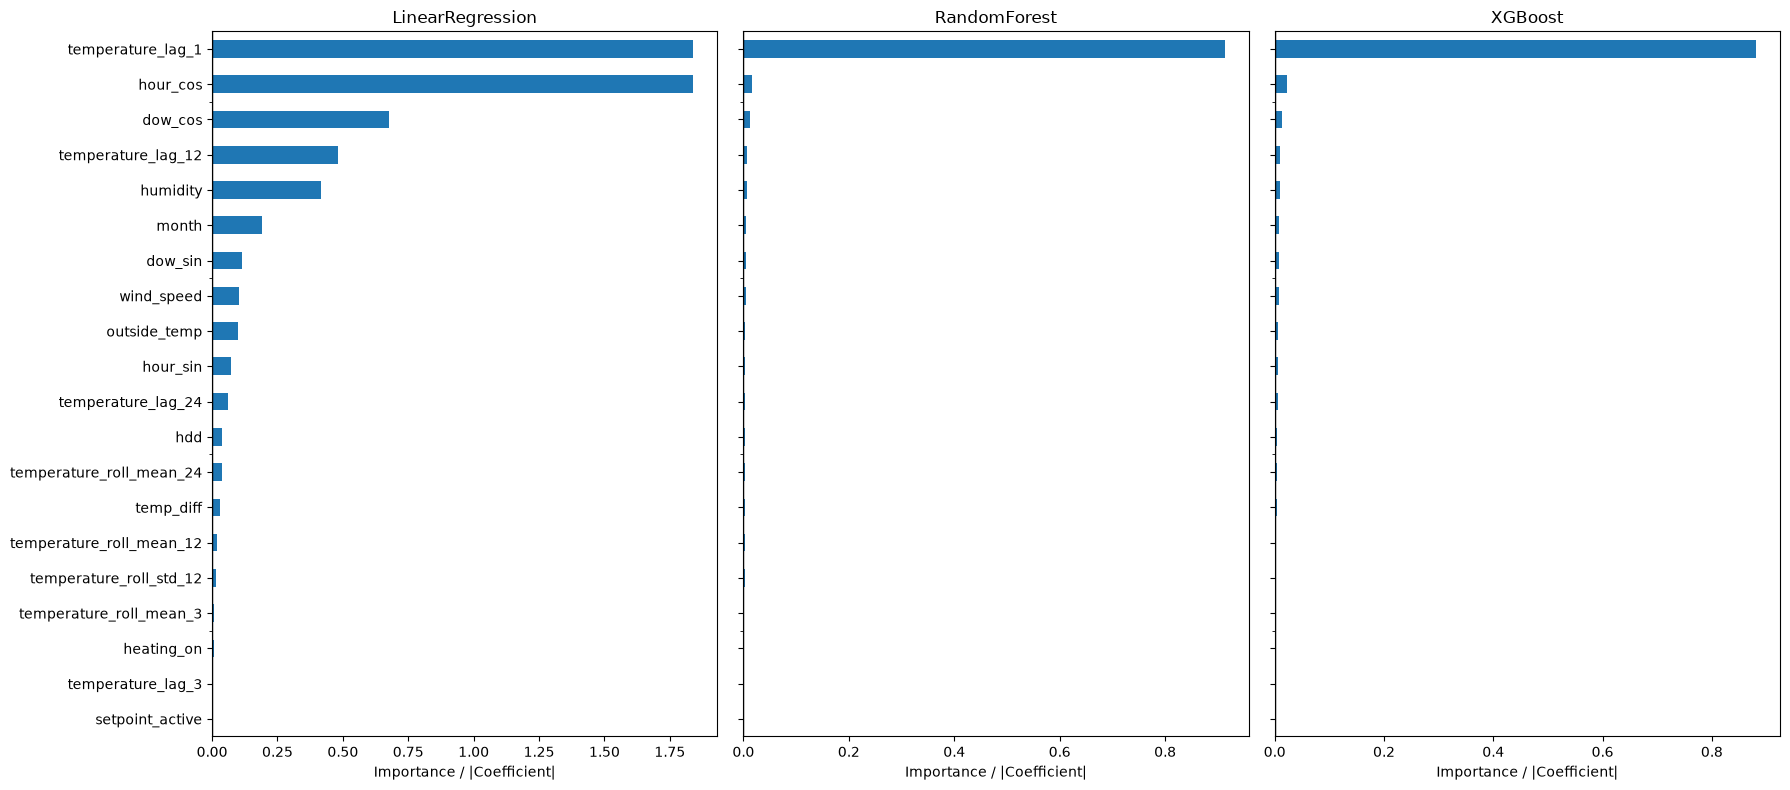

In [9]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(18, 8), sharey=True)
models = get_models()

for ax, (name, model) in zip(axes, models.items()):
    model.fit(X_train, y_train)
    
    # Get importance based on model type
    if hasattr(model, "feature_importances_"):
        imp = pd.Series(model.feature_importances_, index=FEATURE_COLS)
    else:
        # Use absolute coefficients so magnitude is comparable to tree importance
        imp = pd.Series(np.abs(model.coef_), index=FEATURE_COLS)
    
    imp.sort_values().plot.barh(ax=ax)
    ax.set_title(name)
    ax.axvline(0, color="black", lw=1)
    ax.set_xlabel("Importance / |Coefficient|")

plt.tight_layout()
plt.show()

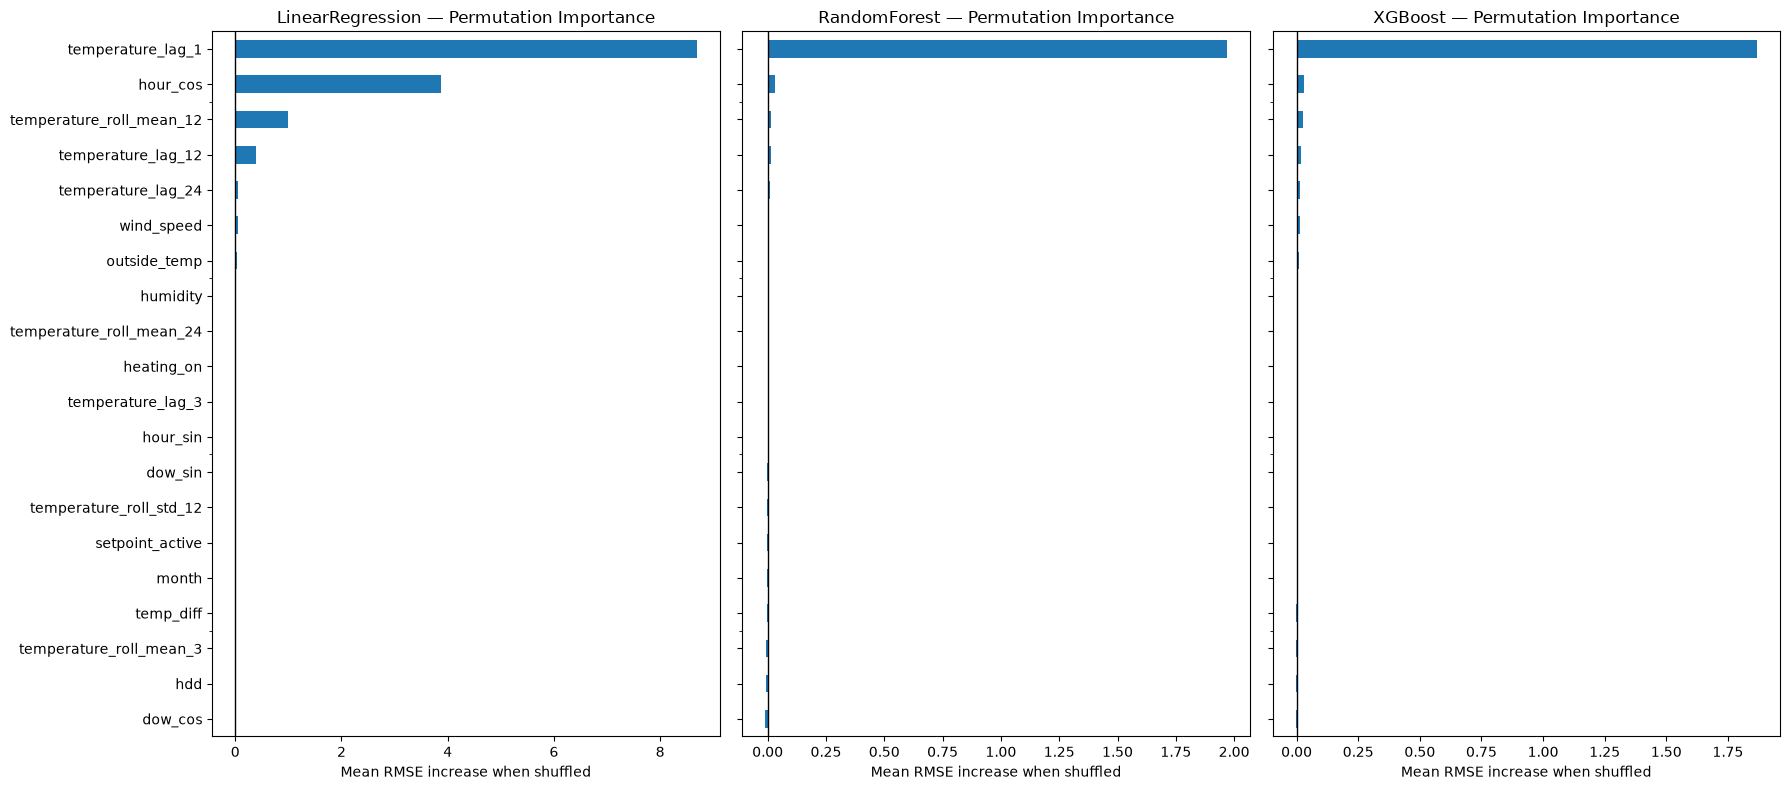

In [10]:
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import pandas as pd

fig, axes = plt.subplots(1, 3, figsize=(18, 8), sharey=True)
models = get_models()

for ax, (name, model) in zip(axes, models.items()):
    model.fit(X_train, y_train)
    result = permutation_importance(
        model, X_test, y_test,
        n_repeats=10, random_state=42, n_jobs=-1
    )
    imp = pd.Series(result.importances_mean, index=FEATURE_COLS)
    imp.sort_values().plot.barh(ax=ax)
    ax.set_title(f"{name} — Permutation Importance")
    ax.axvline(0, color="black", lw=1)
    ax.set_xlabel("Mean RMSE increase when shuffled")

plt.tight_layout()
plt.show()

Further Experiments

In [11]:
FEATURE_COLS_NO_LEAK = [c for c in FEATURE_COLS if c != "temperature_lag_1"]

X_train_no_leak = train[FEATURE_COLS_NO_LEAK]
X_test_no_leak  = test[FEATURE_COLS_NO_LEAK]

results_no_leak = []
for name, model in get_models().items():
    model.fit(X_train_no_leak, y_train)
    p = model.predict(X_test_no_leak)
    results_no_leak.append(evaluate(y_test, p, f"{name} (no lag_1)"))

res_no_leak_df = pd.DataFrame(results_no_leak).sort_values("RMSE")
print(res_no_leak_df.to_string(index=False))

                      model     RMSE      MAE       R2
LinearRegression (no lag_1) 0.362897 0.267294 0.882281
         XGBoost (no lag_1) 0.464195 0.364688 0.807390
    RandomForest (no lag_1) 0.483009 0.373933 0.791460
